# Período de un péndulo y validez de la aproximación de ángulos pequeños

Notebook limpio para Google Colab (y ejecución local) que analiza las trayectorias a **60 fps** (`results/trajectories.csv`) alineado con `src/labo13/pendulum_analysis.py`:
1. **Configuración, carga de datos y conversión angular** usando el punto de suspensión medido directamente en el fotograma 4K $(x_p, y_p) = (1960; 37)\,\text{px}$ (con validación cruzada mediante arco circular) y la longitud real del péndulo $L = (107{,}2 \pm 0{,}5)\,\text{cm}$.
2. **Ajuste sinusoidal sin amortiguamiento en dos etapas (doble ajuste)** inicializado por FFT con *zero-padding* y cuadrados mínimos lineales, más verificación libre de modelo del decaimiento de amplitud pico a pico (`scipy.signal.find_peaks`) para las 14 tomas activas (`Toma 1` a `Toma 14`).
3. **Comparación general** de $T(\theta_0)$ frente al límite experimental $T_0$, la predicción teórica $T_{0,\text{teo}} = 2\pi\sqrt{L/g}$ y la expansión no lineal de Borda.
4. **Visualización de figuras de publicación** sin títulos internos en Matplotlib (los títulos van en `\subcaption` y `\caption` de LaTeX).

## 0. Configuración, carga de datos y funciones de ajuste

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit, least_squares
from scipy.signal import find_peaks
from IPython.display import display

# --- Constantes físicas del péndulo ---
LARGO_PENDULO = 107.2 / 100.0          # [m] longitud real medida del péndulo (107,2 cm)
SIGMA_L = 0.5 / 100.0                  # [m] incerteza de la longitud (0,5 cm)
SIGMA_C = 0.2 / 1000.0                 # [m] incerteza del calibre
G_REF = 9.797                          # [m/s²] gravedad local de referencia

# --- Punto de suspensión medido directamente en el fotograma 4K (3840x2160) ---
X_PIVOT_PX = 1960.0                    # [px]
Y_PIVOT_PX = 37.0                      # [px]

# --- Parámetros de cámara ---
FPS = 60.0
SIGMA_T = 1.0 / FPS                    # [s] período entre fotogramas (~16,67 ms)

# --- Videos excluidos temporalmente ---
EXCLUDED_VIDEOS = {"IMG_1569"}

# --- Carga de trajectories.csv (local o Google Drive en Colab) ---
DRIVE_FILE_ID = "1hpsoMIAV7MEFq7sY5r-pHIDj240V9jl5"
LOCAL_CANDIDATES = [
    Path("results/trajectories.csv"),
    Path("../results/trajectories.csv"),
    Path("trajectories.csv"),
]

csv_source = next((p for p in LOCAL_CANDIDATES if p.exists()), None)
if csv_source is not None:
    df_all = pd.read_csv(csv_source)
    print(f"CSV cargado localmente desde: {csv_source} ({len(df_all)} filas)")
else:
    drive_url = f"https://drive.google.com/uc?id={DRIVE_FILE_ID}"
    df_all = pd.read_csv(drive_url)
    print(f"CSV cargado desde Google Drive ID={DRIVE_FILE_ID} ({len(df_all)} filas)")

df_active = df_all[~df_all["video_name"].isin(EXCLUDED_VIDEOS)].copy()
resumen_videos = (
    df_active.groupby("video_name", sort=True)
    .agg(
        fotogramas=("t", "size"),
        validos=("x", lambda s: int(s.notna().sum())),
        t_ini=("t", "min"),
        t_fin=("t", "max"),
        x_min=("x", "min"),
        x_max=("x", "max"),
        y_min=("y", "min"),
        y_max=("y", "max"),
    )
)
print(f"Videos activos analizados: {len(resumen_videos)} (excluidos: {sorted(EXCLUDED_VIDEOS)})")
display(resumen_videos)

CSV cargado localmente desde: ../results/trajectories.csv (16517 filas)
Videos activos analizados: 14 (excluidos: ['IMG_1569'])


,fotogramas,validos,t_ini,t_fin,x_min,x_max,y_min,y_max
video_name,,,,,,,,
IMG_1555,1320,1307,0.0,21.9833,276.0,3681.0,1090.0,2042.0
IMG_1556,1020,1020,2.0,18.9833,559.0,3409.0,1417.0,2043.0
IMG_1557,1118,1118,1.0,19.6167,747.0,3188.0,1605.0,2037.0
IMG_1558,1155,1155,0.0,19.2333,1124.0,2780.0,1843.0,2039.0
IMG_1559,1012,1012,2.0,18.8500,1319.0,2598.0,1909.0,2039.0
IMG_1560,1217,1217,0.0,20.2667,1388.0,2507.0,1942.0,2035.0
IMG_1561,1039,1039,2.0,19.3000,1503.0,2396.0,1971.0,2035.0
IMG_1562,900,900,2.0,16.9833,1586.0,2316.0,1986.0,2034.0
IMG_1563,1270,1270,2.0,23.1500,1555.0,2344.0,1981.0,2031.0


### 0.1. Clase `GravedadCalculada` (conservada del Colab original)

In [2]:
import itertools
from pathlib import Path
import av
import skimage
from tqdm.auto import tqdm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import chi2

# ==============================================================================
# 1. CLASE ACTUALIZADA CON ERRORES (X, Y, t), CHI CUADRADO Y AMBOS MODELOS
# ==============================================================================
class GravedadCalculada:
    def __init__(
        self,
        df_polar: pd.DataFrame,
        nombre: str = "Experimento",
        con_amortiguamiento: bool = True,
        largo_base: float = LARGO_PENDULO,
        largo_sin_base: float = LARGO_PENDULO,
        sigma_l: float = SIGMA_L,
        sigma_t: float = SIGMA_T,
    ):
        self.nombre = nombre
        self.con_amortiguamiento = con_amortiguamiento
        self.tipo_modelo = "Con Amort." if con_amortiguamiento else "Sin Amort."
        self.largo_base = largo_base
        self.largo_sin_base = largo_sin_base
        self.largo_cm = 0.5 * (largo_base + largo_sin_base)
        self.sigma_l = sigma_l
        self.sigma_t = sigma_t

        self.df_polar = df_polar
        self.df_fit = df_polar.dropna(
            subset=["t", "theta_rad", "sigma_theta_stat_rad"]
        ).copy()

        self.t_data = self.df_fit["t"].values
        self.y_data = self.df_fit["theta_rad"].values
        # Error estadístico (x, y) punto a punto para el ajuste
        self.y_err_stat = self.df_fit["sigma_theta_stat_rad"].values
        # Error total (incluyendo sistemático de L y escala k)
        self.y_err_total = self.df_fit["sigma_theta_total_rad"].values

        self._ajustar()

    # --- PROCESAMIENTO DE VIDEO ---
    @staticmethod
    def _procesar_fotograma(
        fotograma_gray: np.ndarray,
        recorte_y: tuple[int, int] = (800, 950),
        footprint=skimage.morphology.disk(16),
        umbral: float = 220,
    ) -> tuple[float, float]:
        y_ini, y_fin = recorte_y
        imagen = fotograma_gray.T[y_ini:y_fin]
        imagen = skimage.morphology.closing(imagen, footprint)
        pos = skimage.measure.centroid(imagen < umbral)
        return pos[1], pos[0]  # (x, y)

    @classmethod
    def extraer_xy_video(
        cls,
        archivo: str | Path,
        completo: bool = False,
        paso: int = 10,
        n_fotogramas: int | None = None,
        recorte_y: tuple[int, int] = (800, 950),
        umbral: float = 220,
        radio_disco: int = 16,
    ) -> pd.DataFrame:
        """Extrae (t, x, y) una sola vez para poder ajustar ambos modelos rápido."""
        footprint = skimage.morphology.disk(radio_disco)
        paso_real = 1 if completo else paso
        modo_str = "Completo" if completo else f"Sampleado x{paso}"

        with av.open(archivo) as container:
            video = container.streams.video[0]
            iter_video = container.decode(video=0)
            iter_video = itertools.islice(iter_video, 0, n_fotogramas, paso_real)

            total = None
            if completo and video.frames > 0:
                total = video.frames if n_fotogramas is None else min(video.frames, n_fotogramas)

            data = {"t": [], "x": [], "y": []}
            for fotograma in tqdm(iter_video, total=total, desc=f"[{modo_str}] {Path(archivo).stem}", leave=False):
                x, y = cls._procesar_fotograma(
                    fotograma.to_ndarray(format="gray"),
                    recorte_y=recorte_y,
                    footprint=footprint,
                    umbral=umbral,
                )
                data["t"].append(fotograma.time)
                data["x"].append(x)
                data["y"].append(y)

        return pd.DataFrame(data)

    # --- PASAJE A POLARES USANDO TANTO X COMO Y + PROPAGACIÓN DE ERRORES ---
    @staticmethod
    def xy_a_polar(
        df_xy: pd.DataFrame,
        d_real: float = 0.0450,
        d_px: float = 52.0,
        sigma_d_real: float = SIGMA_C,
        sigma_d_px: float = 1.0,
        sigma_x_px: float = 0.5,
        sigma_y_px: float = 0.5,
        largo_ef: float = 0.5 * (LARGO_PENDULO + LARGO_PENDULO),
        sigma_l: float = SIGMA_L,
        sigma_t: float = SIGMA_T,
    ) -> pd.DataFrame:
        """
        Transforma (x, y) a coordenadas polares (r, theta) propagando:
        - Errores estadísticos punto a punto (sigma_x_px, sigma_y_px) -> para curve_fit y Chi2.
        - Errores sistemáticos de escala (sigma_k) y largo (sigma_L) -> para la incertidumbre total.
        """
        df_p = df_xy.dropna(subset=["t", "x", "y"]).copy()

        # Factor de escala k [m/px] y su error sistemático
        k = d_real / d_px
        sigma_k = k * np.sqrt((sigma_d_real / d_real) ** 2 + (sigma_d_px / d_px) ** 2)

        # Punto de equilibrio (x0, y0) en el punto más bajo de la trayectoria
        x0_px = 0.5 * (df_p["x"].max() + df_p["x"].min())
        # En la imagen y crece hacia abajo: el punto más bajo tiene y máximo
        y0_px = df_p["y"].max()

        dx_px = df_p["x"] - x0_px
        dy_px = y0_px - df_p["y"]  # Elevación vertical positiva hacia arriba [px]

        # Coordenadas cartesianas desde el pivote (X horizontal, Y vertical hacia abajo)
        X_m = dx_px * k
        Y_m = largo_ef - (dy_px * k)
        R_m = np.sqrt(X_m**2 + Y_m**2)

        # Ángulo polar usando AMBAS coordenadas X e Y: theta = arctan2(X, Y)
        df_p["X_m"] = X_m
        df_p["Y_m"] = Y_m
        df_p["R_m"] = R_m
        df_p["theta_rad"] = np.arctan2(X_m, Y_m)
        df_p["theta_deg"] = np.degrees(df_p["theta_rad"])

        # 1. Error ESTADÍSTICO en X e Y (solo debido a la detección del centroide en x e y)
        sigma_X_stat = k * sigma_x_px
        sigma_Y_stat = k * sigma_y_px

        # Derivadas parciales de theta = arctan(X / Y):
        # d(theta)/dX = Y / R^2  ;  d(theta)/dY = -X / R^2
        dtheta_dX = Y_m / (R_m**2)
        dtheta_dY = -X_m / (R_m**2)

        df_p["sigma_theta_stat_rad"] = np.sqrt(
            (dtheta_dX * sigma_X_stat) ** 2 + (dtheta_dY * sigma_Y_stat) ** 2
        )

        # 2. Error TOTAL (sumando errores sistemáticos de escala k y longitud L)
        sigma_X_tot = np.sqrt(sigma_X_stat**2 + (dx_px * sigma_k) ** 2)
        sigma_Y_tot = np.sqrt(sigma_Y_stat**2 + (dy_px * sigma_k) ** 2 + sigma_l**2)

        df_p["sigma_theta_total_rad"] = np.sqrt(
            (dtheta_dX * sigma_X_tot) ** 2 + (dtheta_dY * sigma_Y_tot) ** 2
        )
        df_p["sigma_t"] = sigma_t

        return df_p

    # --- MODELOS MATEMÁTICOS ---
    @staticmethod
    def modelo_amortiguado(t, A, gamma, omega, phi, offset):
        return A * np.exp(-gamma * t) * np.cos(omega * t + phi) + offset

    @staticmethod
    def modelo_sin_amortiguar(t, A, omega, phi, offset):
        return A * np.cos(omega * t + phi) + offset

    def evaluar_modelo(self, t):
        if self.con_amortiguamiento:
            return self.modelo_amortiguado(t, *self.popt)
        return self.modelo_sin_amortiguar(t, *self.popt)

    # --- AJUSTE EN 2 ETAPAS (CON VARIANZA EFECTIVA EN TIEMPO) Y CHI CUADRADO ---
    def _ajustar(self):
        A_init = 0.5 * (self.y_data.max() - self.y_data.min())
        omega_init = np.sqrt(9.8 / self.largo_cm)
        phi_init = 0.0 if self.y_data[0] > np.mean(self.y_data) else np.pi
        offset_init = np.mean(self.y_data)

        if self.con_amortiguamiento:
            func = self.modelo_amortiguado
            p0 = [A_init, 0.003, omega_init, phi_init, offset_init]
        else:
            func = self.modelo_sin_amortiguar
            p0 = [A_init, omega_init, phi_init, offset_init]

        # Etapa 1: Ajuste preliminar con error estadístico de (x, y)
        popt_1, _ = curve_fit(
            func, self.t_data, self.y_data, p0=p0,
            sigma=self.y_err_stat, absolute_sigma=True, maxfev=10000
        )

        # Etapa 2: Propagamos el error de frame/obturación temporal (sigma_t_frame)
        # Durante la exposición de un fotograma (~1/(2*fps)), el movimiento borroso aporta error
        sigma_t_ef = 0.25 * self.sigma_t
        if self.con_amortiguamiento:
            A_1, gamma_1, omega_1, phi_1, _ = popt_1
            dtheta_dt = -A_1 * np.exp(-gamma_1 * self.t_data) * omega_1 * np.sin(omega_1 * self.t_data + phi_1)
        else:
            A_1, omega_1, phi_1, _ = popt_1
            dtheta_dt = -A_1 * omega_1 * np.sin(omega_1 * self.t_data + phi_1)

        self.y_err_ef = np.sqrt(self.y_err_stat**2 + (dtheta_dt * sigma_t_ef) ** 2)

        # Ajuste definitivo ponderado con la varianza efectiva total punto a punto
        self.popt, self.pcov = curve_fit(
            func, self.t_data, self.y_data, p0=popt_1,
            sigma=self.y_err_ef, absolute_sigma=True, maxfev=10000
        )
        perr = np.sqrt(np.diag(self.pcov))

        if self.con_amortiguamiento:
            A_fit, gamma_fit, omega_fit, phi_fit, offset_fit = self.popt
            sigma_A, sigma_gamma, sigma_omega, sigma_phi, sigma_offset = perr
        else:
            A_fit, omega_fit, phi_fit, offset_fit = self.popt
            sigma_A, sigma_omega, sigma_phi, sigma_offset = perr
            gamma_fit, sigma_gamma = 0.0, 0.0

        # Normalizamos signos de amplitud y frecuencia
        if A_fit < 0:
            A_fit = -A_fit
            phi_fit = (phi_fit + np.pi) % (2 * np.pi)
        omega_fit = np.abs(omega_fit)

        if self.con_amortiguamiento:
            self.popt = [A_fit, gamma_fit, omega_fit, phi_fit, offset_fit]
        else:
            self.popt = [A_fit, omega_fit, phi_fit, offset_fit]

        self.A, self.sigma_A = A_fit, sigma_A
        self.gamma, self.sigma_gamma = gamma_fit, sigma_gamma
        self.omega, self.sigma_omega = omega_fit, sigma_omega
        self.phi, self.sigma_phi = phi_fit, sigma_phi
        self.offset, self.sigma_offset = offset_fit, sigma_offset

        # Frecuencia natural omega_0 y Período T
        self.omega_0 = np.sqrt(self.omega**2 + self.gamma**2)
        self.sigma_omega_0 = (
            np.sqrt((self.omega * self.sigma_omega) ** 2 + (self.gamma * self.sigma_gamma) ** 2)
            / self.omega_0
        )
        self.T = (2.0 * np.pi) / self.omega
        self.sigma_T = ((2.0 * np.pi) / (self.omega**2)) * self.sigma_omega

        # Cálculo de Chi cuadrado y grados de libertad
        self.residuos = self.y_data - self.evaluar_modelo(self.t_data)
        self.chi2 = np.sum((self.residuos / self.y_err_ef) ** 2)
        self.dof = len(self.y_data) - len(self.popt)
        self.chi2_red = self.chi2 / self.dof
        self.p_valor = 1.0 - chi2.cdf(self.chi2, self.dof)

        # Gravedad en el centro de masa (acá entra el error sistemático sigma_L)
        self.g, self.sigma_g = self.calcular_g(self.largo_cm)

    def calcular_g(self, valor_L: float) -> tuple[float, float]:
        g_val = valor_L * (self.omega_0**2)
        sigma_g_val = g_val * np.sqrt(
            (self.sigma_l / valor_L) ** 2 + (2.0 * self.sigma_omega_0 / self.omega_0) ** 2
        )
        return g_val, sigma_g_val

    def diccionario_resumen(self) -> dict:
        g_base, _ = self.calcular_g(self.largo_base)
        g_sin, _ = self.calcular_g(self.largo_sin_base)
        return {
            "Video": self.nombre,
            "Modelo": self.tipo_modelo,
            "θ_max [°]": np.degrees(self.A),
            "ω [rad/s]": self.omega,
            "σ_ω [rad/s]": self.sigma_omega,
            "T [s]": self.T,
            "σ_T [s]": self.sigma_T,
            "γ [1/s]": self.gamma,
            "σ_γ [1/s]": self.sigma_gamma,
            "χ²": self.chi2,
            "ν (dof)": self.dof,
            "χ²_red": self.chi2_red,
            "g_CM [m/s²]": self.g,
            "σ_g_CM [m/s²]": self.sigma_g,
            "g_sin_base": g_sin,
            "g_con_base": g_base,
        }

/home/aaron/bs/labo13-nuevos-videos-1080/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# --- Punto de suspensión medido (1960, 37) px y validación cruzada por arco circular ---
VIDEOS_CALIBRACION = ["IMG_1555", "IMG_1556", "IMG_1557", "IMG_1558"]
df_cal = df_active[df_active["video_name"].isin(VIDEOS_CALIBRACION)].dropna(subset=["x", "y"])

radios_medidos = np.hypot(df_cal["x"].to_numpy() - X_PIVOT_PX, df_cal["y"].to_numpy() - Y_PIVOT_PX)
R_MEDIDO_PX = float(np.mean(radios_medidos))
RMS_RADIAL_MEDIDO_PX = float(np.sqrt(np.mean((radios_medidos - R_MEDIDO_PX) ** 2)))

def _residuos_circulo(params: np.ndarray) -> np.ndarray:
    xc, yc, r_px = params
    return np.hypot(df_cal["x"].to_numpy() - xc, df_cal["y"].to_numpy() - yc) - r_px

res_circ = least_squares(_residuos_circulo, x0=[1950.0, 35.0, 1990.0])
XC_FIT_PX, YC_FIT_PX, R_FIT_PX = [float(v) for v in res_circ.x]
RMS_RADIAL_FIT_PX = float(np.sqrt(np.mean(res_circ.fun ** 2)))

print(f"Pivote medido en fotograma 4K: x_p = {X_PIVOT_PX:.1f} px, y_p = {Y_PIVOT_PX:.1f} px (R_medio = {R_MEDIDO_PX:.2f} px)")
print(f"Validación cruzada (arco circular): x_c = {XC_FIT_PX:.2f} px, y_c = {YC_FIT_PX:.2f} px, R = {R_FIT_PX:.2f} px (RMS = {RMS_RADIAL_FIT_PX:.2f} px)")


def modelo_sinusoidal(tau: np.ndarray, A: float, omega: float, phi: float, offset: float) -> np.ndarray:
    """Modelo armónico simple sin amortiguamiento: θ(τ) = A cos(ω τ + φ) + offset."""
    return A * np.cos(omega * tau + phi) + offset


def preparar_serie_angular(df_video: pd.DataFrame) -> pd.DataFrame:
    """Convierte (x, y) [px] en ángulo θ(t) = atan2(x - x_p, y - y_p) respecto de la vertical."""
    df_v = df_video.dropna(subset=["t", "x", "y"]).sort_values("t").copy()
    dx = df_v["x"].to_numpy(dtype=float) - X_PIVOT_PX
    dy = df_v["y"].to_numpy(dtype=float) - Y_PIVOT_PX
    theta_rad = np.arctan2(dx, dy)

    df_v["tau"] = df_v["t"].to_numpy(dtype=float) - float(df_v["t"].iloc[0])
    df_v["theta_rad"] = theta_rad
    df_v["theta_deg"] = np.degrees(theta_rad)
    return df_v


RESULTADOS: dict[str, dict] = {}


def analizar_y_graficar_video(video_name: str, mostrar_grafico: bool = True) -> dict:
    """Ajusta θ(t) = A cos(ω(t - t_0) + φ) + offset en dos etapas (doble ajuste) y mide el decaimiento pico a pico."""
    df_v = preparar_serie_angular(df_active[df_active["video_name"] == video_name])
    t = df_v["t"].to_numpy(dtype=float)
    tau = df_v["tau"].to_numpy(dtype=float)
    theta = df_v["theta_rad"].to_numpy(dtype=float)
    theta_deg = df_v["theta_deg"].to_numpy(dtype=float)

    # 1. Estimación inicial de frecuencia ω por FFT con zero-padding
    dt = float(np.median(np.diff(tau)))
    n_fft = 65536
    freqs = np.fft.rfftfreq(n_fft, d=dt)
    spectrum = np.abs(np.fft.rfft(theta - np.mean(theta), n=n_fft))
    mask_band = (freqs >= 0.2) & (freqs <= 1.5)
    f_init = float(freqs[mask_band][np.argmax(spectrum[mask_band])])
    omega_init = 2.0 * np.pi * f_init

    # 2. Estimación inicial de amplitud, fase y offset por cuadrados mínimos lineales
    X_lin = np.column_stack([np.cos(omega_init * tau), -np.sin(omega_init * tau), np.ones_like(tau)])
    beta, *_ = np.linalg.lstsq(X_lin, theta, rcond=None)
    A_init = float(np.hypot(beta[0], beta[1]))
    phi_init = float(np.arctan2(beta[1], beta[0]))
    offset_init = float(beta[2])

    # 3. Doble ajuste empírico (Etapa 1 sin pesos -> dispersión residual s_res -> Etapa 2 con absolute_sigma=True)
    popt_1, _ = curve_fit(
        modelo_sinusoidal,
        tau,
        theta,
        p0=[A_init, omega_init, phi_init, offset_init],
        maxfev=20000,
    )
    dof = len(tau) - 4
    res_1 = theta - modelo_sinusoidal(tau, *popt_1)
    s_res_rad = float(np.sqrt(np.sum(res_1 ** 2) / float(dof)))

    popt, pcov = curve_fit(
        modelo_sinusoidal,
        tau,
        theta,
        p0=popt_1,
        sigma=np.full_like(theta, max(s_res_rad, 1e-12)),
        absolute_sigma=True,
        maxfev=20000,
    )
    perr = np.sqrt(np.diag(pcov))
    A_fit, omega_fit, phi_fit, offset_fit = [float(v) for v in popt]
    s_A, s_omega, s_phi, s_offset = [float(v) for v in perr]

    if A_fit < 0:
        A_fit = -A_fit
        phi_fit = (phi_fit + np.pi) % (2.0 * np.pi)
    omega_fit = abs(omega_fit)

    T_fit = (2.0 * np.pi) / omega_fit
    s_T = ((2.0 * np.pi) / (omega_fit ** 2)) * s_omega

    theta_pred = modelo_sinusoidal(tau, A_fit, omega_fit, phi_fit, offset_fit)
    residuos_rad = theta - theta_pred
    s_res_final_deg = float(np.degrees(np.sqrt(np.sum(residuos_rad ** 2) / float(dof))))

    # 4. Verificación libre de modelo del decaimiento de amplitud (primer vs último ciclo)
    theta_c = theta_deg - float(np.mean(theta_deg))
    pos_peaks, _ = find_peaks(theta_c, distance=90)
    neg_peaks, _ = find_peaks(-theta_c, distance=90)
    amp_init_deg = 0.5 * float(theta_c[pos_peaks[0]] - theta_c[neg_peaks[0]])
    amp_final_deg = 0.5 * float(theta_c[pos_peaks[-1]] - theta_c[neg_peaks[-1]])
    amp_drop_pct = ((amp_init_deg - amp_final_deg) / amp_init_deg) * 100.0
    n_cycles = int(min(len(pos_peaks), len(neg_peaks)))

    info = {
        "video_name": video_name,
        "n_frames": len(tau),
        "duracion_s": float(t[-1] - t[0]),
        "theta0_rad": A_fit,
        "sigma_theta0_rad": s_A,
        "theta0_deg": float(np.degrees(A_fit)),
        "sigma_theta0_deg": float(np.degrees(s_A)),
        "omega_rad_s": omega_fit,
        "sigma_omega_rad_s": s_omega,
        "T_s": T_fit,
        "sigma_T_s": s_T,
        "offset_deg": float(np.degrees(offset_fit)),
        "s_res_deg": s_res_final_deg,
        "rms_res_deg": float(np.degrees(np.std(residuos_rad))),
        "dof": dof,
        "n_cycles": n_cycles,
        "amp_init_deg": amp_init_deg,
        "amp_final_deg": amp_final_deg,
        "amp_drop_pct": amp_drop_pct,
        "t": t,
        "tau": tau,
        "theta_deg": theta_deg,
        "residuos_deg": np.degrees(residuos_rad),
        "popt": (A_fit, omega_fit, phi_fit, offset_fit),
    }
    RESULTADOS[video_name] = info

    print(
        f"{video_name}: θ_0 = ({info['theta0_deg']:.3f} ± {info['sigma_theta0_deg']:.3f})° | "
        f"T = ({info['T_s']:.5f} ± {info['sigma_T_s']:.5f}) s | "
        f"s_res = {info['s_res_deg']:.3f}° (ν = {dof}) | "
        f"decaimiento pico a pico = {amp_drop_pct:.2f}% ({n_cycles} ciclos)"
    )

    if mostrar_grafico:
        tau_fine = np.linspace(0.0, float(tau[-1]), 1200)
        t_fine = float(t[0]) + tau_fine
        fit_fine_deg = np.degrees(modelo_sinusoidal(tau_fine, *info["popt"]))

        fig, (ax_top, ax_bot) = plt.subplots(
            2, 1, figsize=(8.2, 4.5), sharex=True, gridspec_kw={"height_ratios": [2.5, 1.1]}
        )
        ax_top.plot(t, info["theta_deg"], "o", markersize=2.3, color="black", alpha=0.55, label="Datos experimentales")
        ax_top.plot(t_fine, fit_fine_deg, color="#d62728", lw=1.5, label="Ajuste sinusoidal")
        ax_top.set_ylabel(r"$\theta$ [$^\circ$]")
        ax_top.legend(loc="upper right", fontsize=8.5)
        ax_top.grid(True, alpha=0.25)

        ax_bot.plot(t, info["residuos_deg"], "o", markersize=2.0, color="#1f77b4", alpha=0.65)
        ax_bot.axhline(0.0, color="black", linestyle="--", lw=0.9)
        ax_bot.set_ylabel(r"Residuo [$^\circ$]")
        ax_bot.set_xlabel(r"$t$ [s]")
        ax_bot.grid(True, alpha=0.25)

        fig.tight_layout()
        plt.show()

    return info

Pivote medido en fotograma 4K: x_p = 1960.0 px, y_p = 37.0 px (R_medio = 1988.75 px)
Validación cruzada (arco circular): x_c = 1988.36 px, y_c = 35.57 px, R = 1990.08 px (RMS = 9.53 px)


## 1. Ajustes individuales por video

Cada toma se analiza y grafica por separado con el modelo armónico simple $\theta(t) = A\cos(\omega(t - t_0) + \phi) + \theta_{\text{offset}}$ (sin títulos internos en las figuras).

### 1.1. Toma `IMG_1555`

IMG_1555: θ_0 = (56.340 ± 0.093)° | T = (2.20335 ± 0.00020) s | s_res = 2.359° (ν = 1303) | decaimiento pico a pico = 9.50% (10 ciclos)


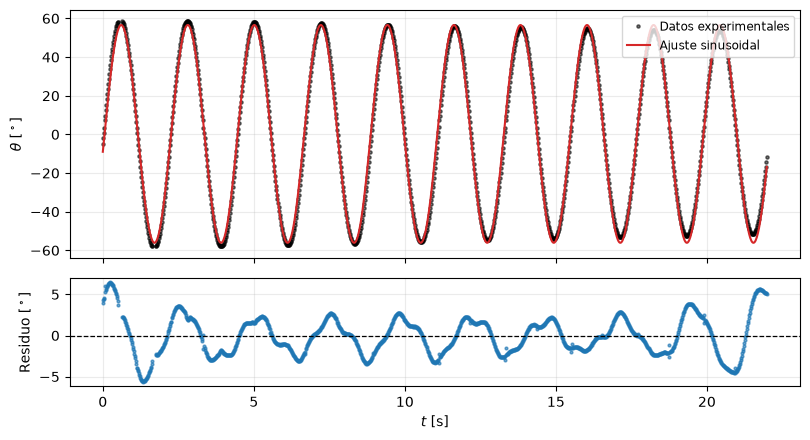

In [4]:
_ = analizar_y_graficar_video("IMG_1555")

### 1.2. Toma `IMG_1556`

IMG_1556: θ_0 = (44.151 ± 0.045)° | T = (2.15125 ± 0.00016) s | s_res = 1.018° (ν = 1016) | decaimiento pico a pico = 7.70% (8 ciclos)


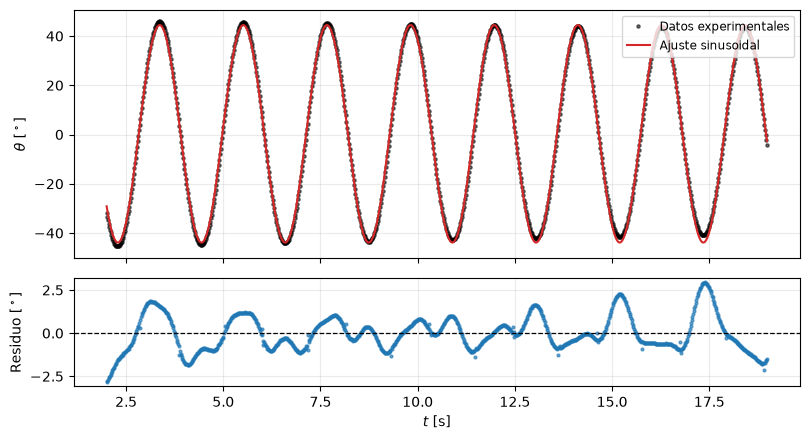

In [5]:
_ = analizar_y_graficar_video("IMG_1556")

### 1.3. Toma `IMG_1557`

IMG_1557: θ_0 = (36.574 ± 0.029)° | T = (2.12671 ± 0.00011) s | s_res = 0.692° (ν = 1114) | decaimiento pico a pico = 7.21% (9 ciclos)


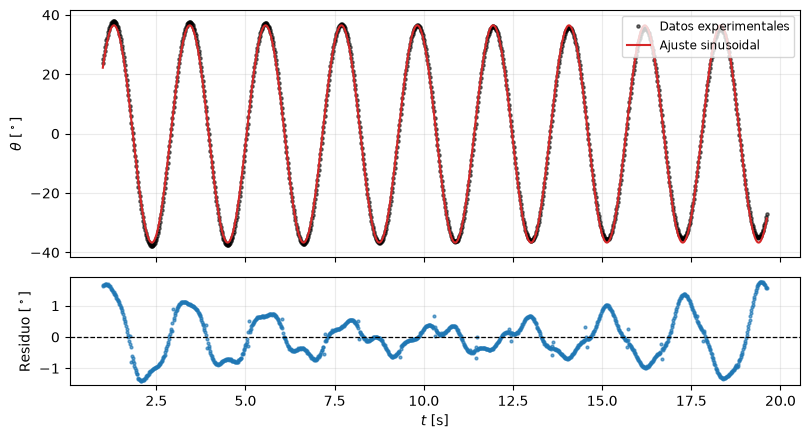

In [6]:
_ = analizar_y_graficar_video("IMG_1557")

### 1.4. Toma `IMG_1558`

IMG_1558: θ_0 = (23.952 ± 0.014)° | T = (2.09659 ± 0.00007) s | s_res = 0.336° (ν = 1151) | decaimiento pico a pico = 5.59% (9 ciclos)


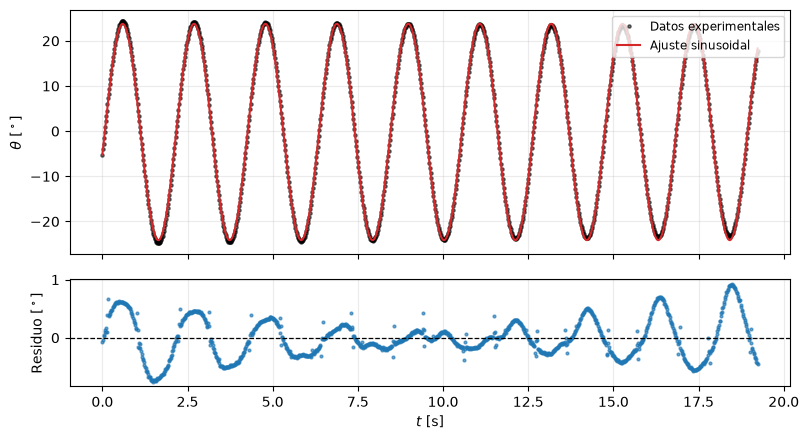

In [7]:
_ = analizar_y_graficar_video("IMG_1558")

### 1.5. Toma `IMG_1559`

IMG_1559: θ_0 = (18.372 ± 0.009)° | T = (2.08725 ± 0.00007) s | s_res = 0.210° (ν = 1008) | decaimiento pico a pico = 4.45% (8 ciclos)


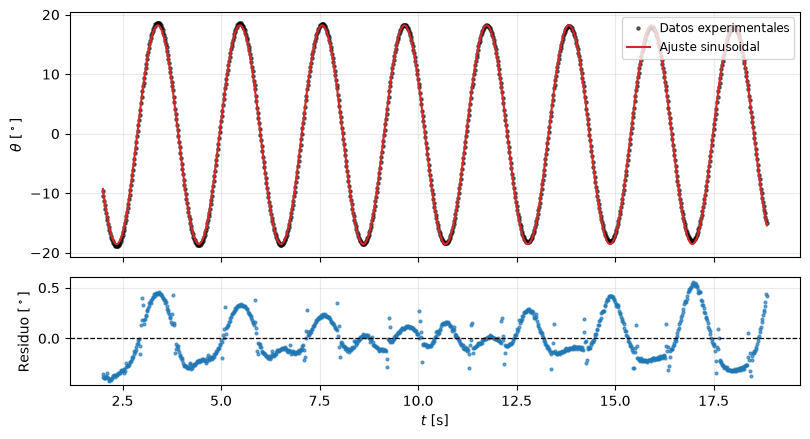

In [8]:
_ = analizar_y_graficar_video("IMG_1559")

### 1.6. Toma `IMG_1560`

IMG_1560: θ_0 = (15.988 ± 0.008)° | T = (2.08384 ± 0.00006) s | s_res = 0.187° (ν = 1213) | decaimiento pico a pico = 4.68% (10 ciclos)


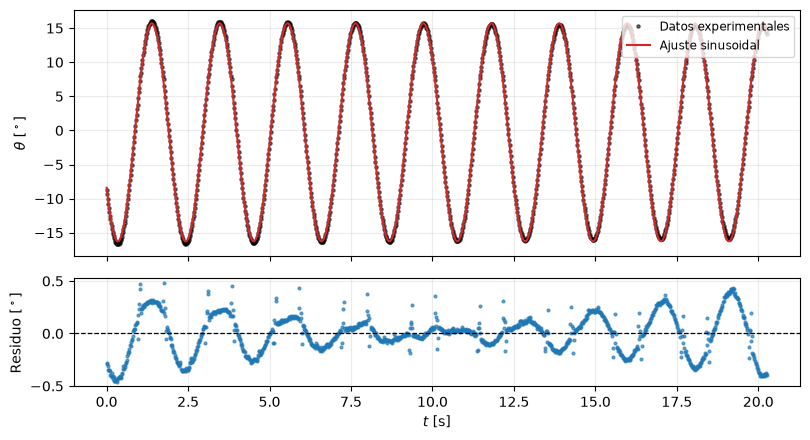

In [9]:
_ = analizar_y_graficar_video("IMG_1560")

### 1.7. Toma `IMG_1561`

IMG_1561: θ_0 = (12.785 ± 0.005)° | T = (2.08019 ± 0.00006) s | s_res = 0.122° (ν = 1035) | decaimiento pico a pico = 3.59% (8 ciclos)


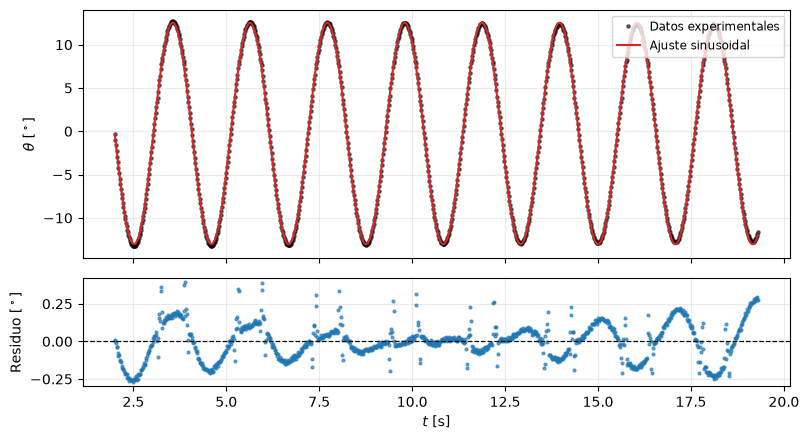

In [10]:
_ = analizar_y_graficar_video("IMG_1561")

### 1.8. Toma `IMG_1562`

IMG_1562: θ_0 = (10.461 ± 0.004)° | T = (2.07798 ± 0.00007) s | s_res = 0.092° (ν = 896) | decaimiento pico a pico = 2.89% (7 ciclos)


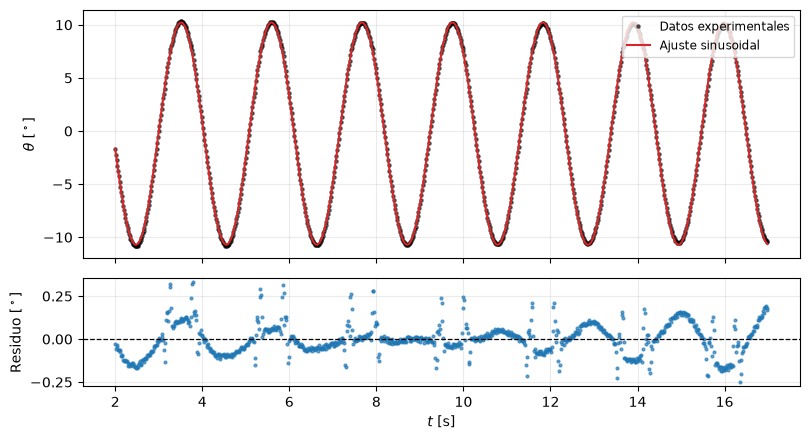

In [11]:
_ = analizar_y_graficar_video("IMG_1562")

### 1.9. Toma `IMG_1563`

IMG_1563: θ_0 = (11.230 ± 0.005)° | T = (2.07854 ± 0.00005) s | s_res = 0.126° (ν = 1266) | decaimiento pico a pico = 4.35% (10 ciclos)


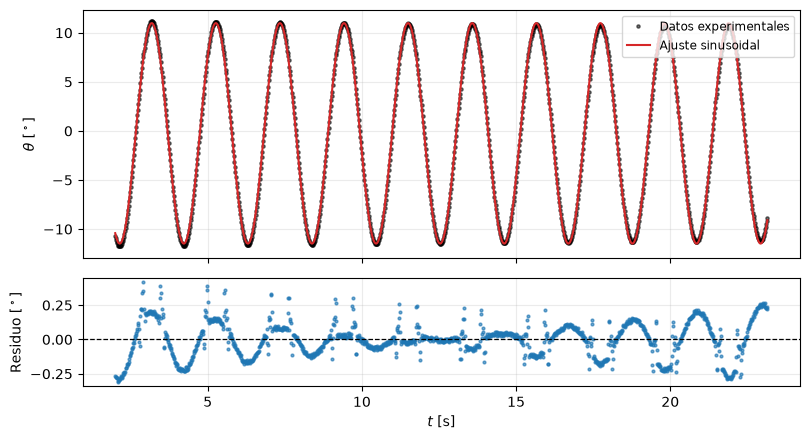

In [12]:
_ = analizar_y_graficar_video("IMG_1563")

### 1.10. Toma `IMG_1564`

IMG_1564: θ_0 = (8.904 ± 0.004)° | T = (2.07650 ± 0.00010) s | s_res = 0.075° (ν = 682) | decaimiento pico a pico = 1.78% (5 ciclos)


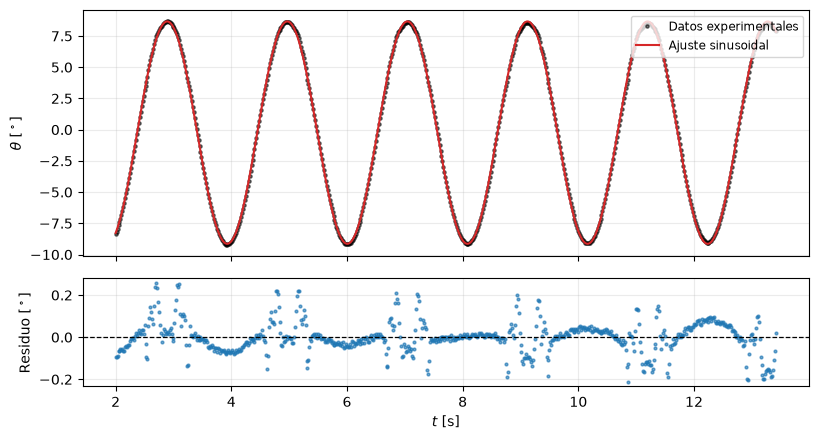

In [13]:
_ = analizar_y_graficar_video("IMG_1564")

### 1.11. Toma `IMG_1565`

IMG_1565: θ_0 = (8.036 ± 0.004)° | T = (2.07578 ± 0.00007) s | s_res = 0.082° (ν = 950) | decaimiento pico a pico = 2.21% (7 ciclos)


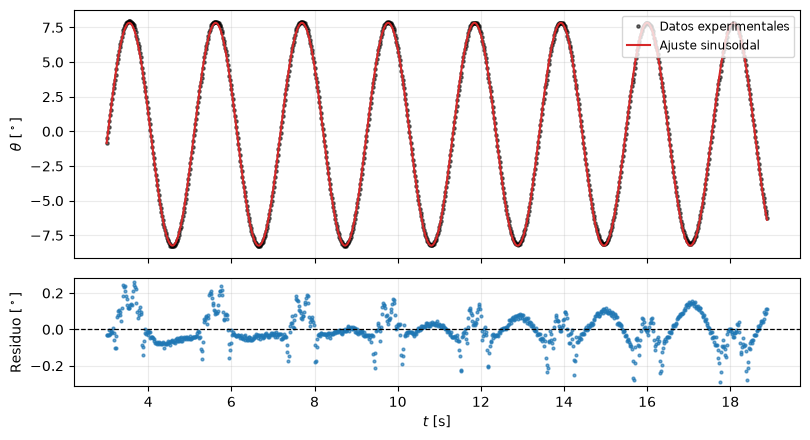

In [14]:
_ = analizar_y_graficar_video("IMG_1565")

### 1.12. Toma `IMG_1566`

IMG_1566: θ_0 = (6.500 ± 0.003)° | T = (2.07473 ± 0.00005) s | s_res = 0.068° (ν = 1171) | decaimiento pico a pico = 2.86% (9 ciclos)


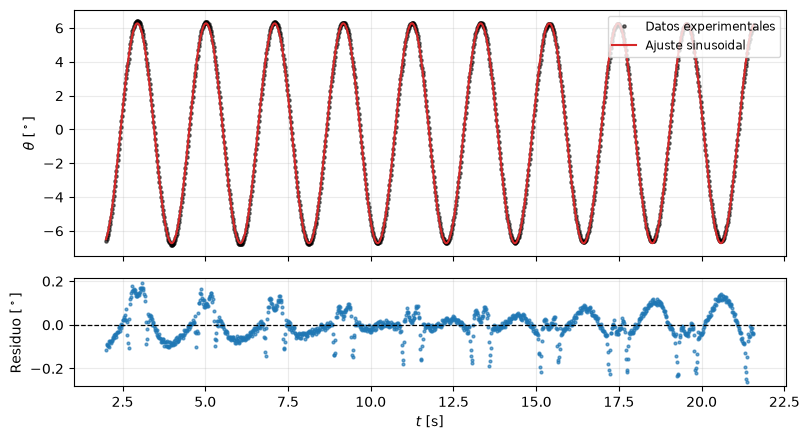

In [15]:
_ = analizar_y_graficar_video("IMG_1566")

### 1.13. Toma `IMG_1567`

IMG_1567: θ_0 = (3.782 ± 0.001)° | T = (2.07318 ± 0.00003) s | s_res = 0.048° (ν = 2116) | decaimiento pico a pico = 5.63% (17 ciclos)


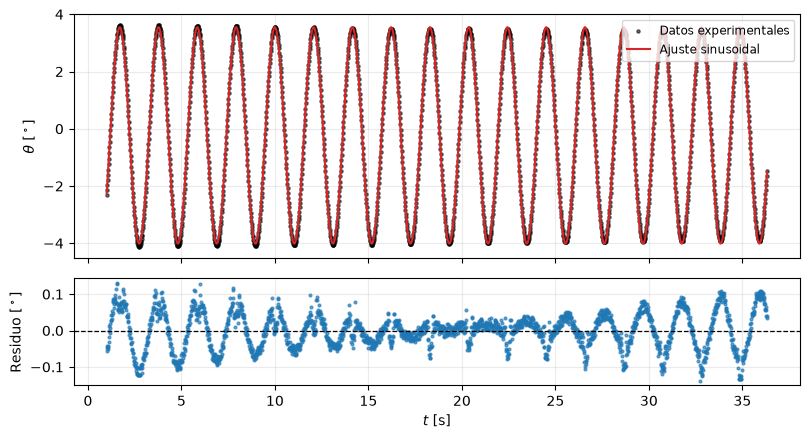

In [16]:
_ = analizar_y_graficar_video("IMG_1567")

### 1.14. Toma `IMG_1568`

IMG_1568: θ_0 = (2.166 ± 0.001)° | T = (2.07254 ± 0.00006) s | s_res = 0.014° (ν = 807) | decaimiento pico a pico = 1.98% (6 ciclos)


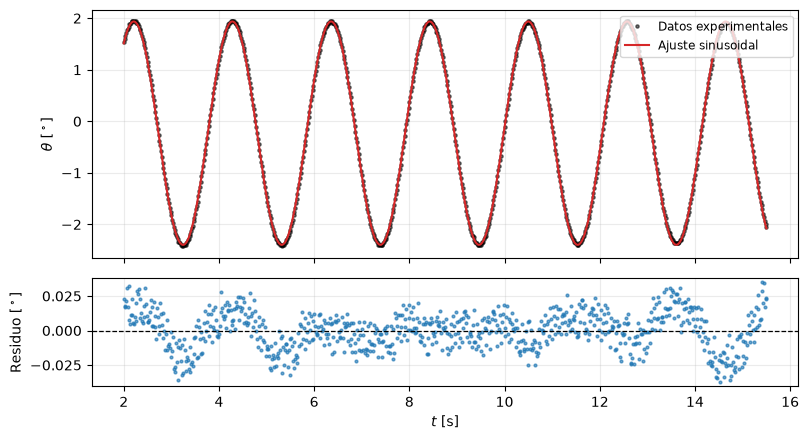

In [17]:
_ = analizar_y_graficar_video("IMG_1568")

### 1.15. Toma `IMG_1569` (excluida temporalmente para revisión manual)

Esta toma se ignora mientras `"IMG_1569"` esté en `EXCLUDED_VIDEOS`. Una vez verificado el recorte en `notebooks/debug_frame_detection.ipynb` y regenerado `results/trajectories.csv`, basta con quitar `"IMG_1569"` de `EXCLUDED_VIDEOS` en la sección 0.

In [18]:
if "IMG_1569" in EXCLUDED_VIDEOS:
    print("IMG_1569 excluido temporalmente (pendiente de verificación manual en debug_frame_detection.ipynb).")
else:
    _ = analizar_y_graficar_video("IMG_1569")

IMG_1569 excluido temporalmente (pendiente de verificación manual en debug_frame_detection.ipynb).


## 2. Comparación general y validez de la aproximación de ángulos pequeños

In [19]:
# --- Tabla resumen ordenada en orden decreciente de amplitud (Toma 1 = mayor ángulo ... Toma 14 = menor ángulo) ---
orden_desc = sorted(RESULTADOS.items(), key=lambda item: item[1]["theta0_deg"], reverse=True)

# --- Período de referencia de pequeñas oscilaciones (T_0) ---
_, info_ref = orden_desc[-1]
TOMA_REF = f"Toma {len(orden_desc)}"
T_REF_OBS = float(info_ref["T_s"])
SIGMA_T0_REF = float(info_ref["sigma_T_s"])
theta_ref_rad = float(info_ref["theta0_rad"])
T0_BORDA_LIM = T_REF_OBS / (1.0 + (theta_ref_rad ** 2) / 16.0)

# --- Predicción teórica con la longitud real L = (107,2 ± 0,5) cm ---
T0_TEO_L = 2.0 * np.pi * np.sqrt(LARGO_PENDULO / G_REF)
SIGMA_T0_TEO_L = 0.5 * T0_TEO_L * (SIGMA_L / LARGO_PENDULO)
DIFF_TEO_EXP_MS = (T0_TEO_L - T0_BORDA_LIM) * 1e3
Z_TEO_EXP = abs(T0_TEO_L - T0_BORDA_LIM) / np.hypot(SIGMA_T0_TEO_L, SIGMA_T0_REF)

filas_resumen = []
filas_decaimiento = []
for idx, (vname, info) in enumerate(orden_desc, start=1):
    toma_lbl = f"Toma {idx}"
    delta_t_ms = (info["T_s"] - T0_BORDA_LIM) * 1e3
    sigma_dt_ms = float(np.hypot(info["sigma_T_s"], SIGMA_T0_REF) * 1e3)
    z_score = abs(delta_t_ms) / sigma_dt_ms
    t_borda = T0_BORDA_LIM * (
        1.0 + (info["theta0_rad"] ** 2) / 16.0 + (11.0 * (info["theta0_rad"] ** 4)) / 3072.0
    )
    filas_resumen.append(
        {
            "Toma": toma_lbl,
            "Video": vname,
            "Fotogramas": info["n_frames"],
            "Duración [s]": info["duracion_s"],
            "θ_0 [°]": info["theta0_deg"],
            "σ_θ0 [°]": info["sigma_theta0_deg"],
            "T [s]": info["T_s"],
            "σ_T [s]": info["sigma_T_s"],
            "s_res [°]": info["s_res_deg"],
            "ΔT = T - T_0 [ms]": delta_t_ms,
            "σ_ΔT [ms]": sigma_dt_ms,
            "3σ_ΔT [ms]": 3.0 * sigma_dt_ms,
            "|ΔT| / σ_ΔT": z_score,
            "Compatible (3σ)": "Sí" if z_score <= 3.0 else "No",
            "T - T_Borda [ms]": (info["T_s"] - t_borda) * 1e3,
        }
    )
    filas_decaimiento.append(
        {
            "Toma": toma_lbl,
            "θ_0 [°]": info["theta0_deg"],
            "Duración [s]": info["duracion_s"],
            "Ciclos": info["n_cycles"],
            "A_ini [°]": info["amp_init_deg"],
            "A_fin [°]": info["amp_final_deg"],
            "Caída [%]": info["amp_drop_pct"],
        }
    )

df_resumen = pd.DataFrame(filas_resumen)
df_decaimiento = pd.DataFrame(filas_decaimiento)

print(
    f"Referencia experimental de pequeñas oscilaciones ({TOMA_REF}, θ_0 = {info_ref['theta0_deg']:.3f}°): "
    f"T_obs = ({T_REF_OBS:.5f} ± {SIGMA_T0_REF:.5f}) s -> límite θ->0: T_0 = ({T0_BORDA_LIM:.5f} ± {SIGMA_T0_REF:.5f}) s"
)
print(
    f"Predicción teórica (L = {LARGO_PENDULO*100:.1f} ± {SIGMA_L*100:.1f} cm, g = {G_REF} m/s²): "
    f"T_0,teo = ({T0_TEO_L:.5f} ± {SIGMA_T0_TEO_L:.5f}) s | Δ = {DIFF_TEO_EXP_MS:.2f} ms ({Z_TEO_EXP:.2f}σ, compatible)"
)
print(
    f"Decaimiento pico a pico en las 14 tomas: {df_decaimiento['Caída [%]'].min():.2f}% a {df_decaimiento['Caída [%]'].max():.2f}%"
)
display(df_resumen.round(5))
display(df_decaimiento.round(3))

Referencia experimental de pequeñas oscilaciones (Toma 14, θ_0 = 2.166°): T_obs = (2.07254 ± 0.00006) s -> límite θ->0: T_0 = (2.07235 ± 0.00006) s
Predicción teórica (L = 107.2 ± 0.5 cm, g = 9.797 m/s²): T_0,teo = (2.07841 ± 0.00485) s | Δ = 6.06 ms (1.25σ, compatible)
Decaimiento pico a pico en las 14 tomas: 1.78% a 9.50%


,Toma,Video,Fotogramas,Duración [s],θ_0 [°],σ_θ0 [°],T [s],σ_T [s],s_res [°],ΔT = T - T_0 [ms],σ_ΔT [ms],3σ_ΔT [ms],|ΔT| / σ_ΔT,Compatible (3σ),T - T_Borda [ms]
0,Toma 1,IMG_1555,1307,21.9833,56.34029,0.09269,2.20335,0.00020,2.35893,131.00205,0.20621,0.61863,635.27963,No,-1.17372
1,Toma 2,IMG_1556,1020,16.9833,44.15122,0.04492,2.15125,0.00016,1.01831,78.90094,0.16474,0.49422,478.93807,No,-0.62561
2,Toma 3,IMG_1557,1118,18.6167,36.57418,0.02900,2.12671,0.00011,0.69157,54.36261,0.12301,0.36903,441.93596,No,0.35323
3,Toma 4,IMG_1558,1155,19.2333,23.95152,0.01405,2.09659,0.00007,0.33551,24.23501,0.09073,0.27220,267.10091,No,1.37426
4,Toma 5,IMG_1559,1012,16.8500,18.37186,0.00932,2.08725,0.00007,0.20962,14.90227,0.09094,0.27281,163.87466,No,1.50689
5,Toma 6,IMG_1560,1217,20.2667,15.98808,0.00752,2.08384,0.00006,0.18661,11.49267,0.07928,0.23783,144.96956,No,1.36233
6,Toma 7,IMG_1561,1039,17.3000,12.78475,0.00534,2.08019,0.00006,0.12193,7.83590,0.08024,0.24073,97.65375,No,1.36866
7,Toma 8,IMG_1563,1270,21.1500,11.23046,0.00498,2.07854,0.00005,0.12644,6.19016,0.07543,0.22628,82.06861,No,1.20307
8,Toma 9,IMG_1562,900,14.9833,10.46076,0.00432,2.07798,0.00007,0.09152,5.62464,0.08570,0.25711,65.63019,No,1.29898
9,Toma 10,IMG_1564,686,11.4167,8.90378,0.00407,2.07650,0.00010,0.07529,4.15076,0.11010,0.33029,37.70159,No,1.01858


,Toma,θ_0 [°],Duración [s],Ciclos,A_ini [°],A_fin [°],Caída [%]
0,Toma 1,56.340,21.983,10,58.187,52.661,9.498
1,Toma 2,44.151,16.983,8,45.719,42.198,7.701
2,Toma 3,36.574,18.617,9,37.808,35.084,7.205
3,Toma 4,23.952,19.233,9,24.606,23.231,5.588
4,Toma 5,18.372,16.850,8,18.773,17.938,4.445
5,Toma 6,15.988,20.267,10,16.367,15.600,4.684
6,Toma 7,12.785,17.300,8,12.996,12.530,3.586
7,Toma 8,11.230,21.150,10,11.468,10.970,4.346
8,Toma 9,10.461,14.983,7,10.599,10.293,2.887
9,Toma 10,8.904,11.417,5,8.949,8.790,1.779


## 3. Figuras de publicación (sin títulos internos en Matplotlib)

Todas las figuras del análisis se generan y exportan **sin `ax.set_title` ni `fig.suptitle`**, colocando los títulos breves en `\subcaption{...}` y la explicación detallada `(a) ..., (b) ...` en `\caption{...}`.

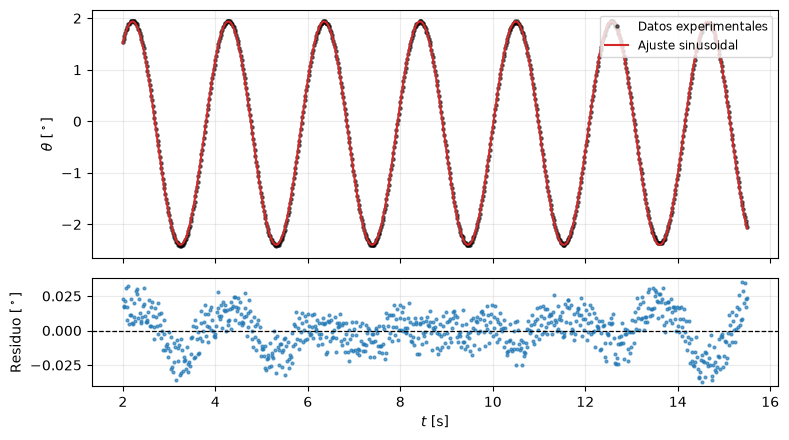

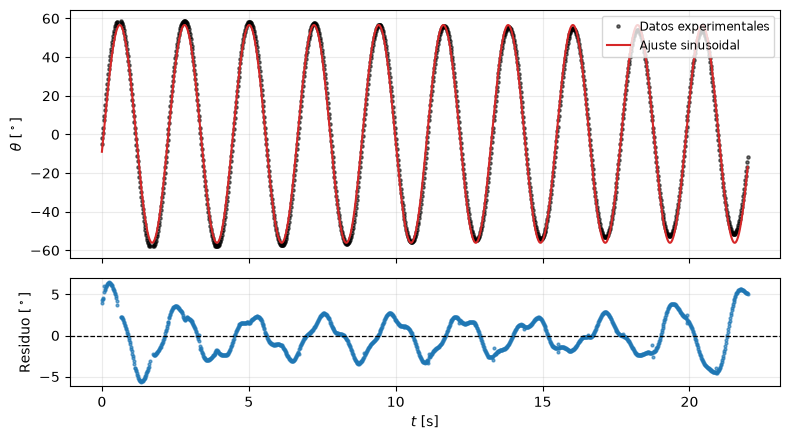

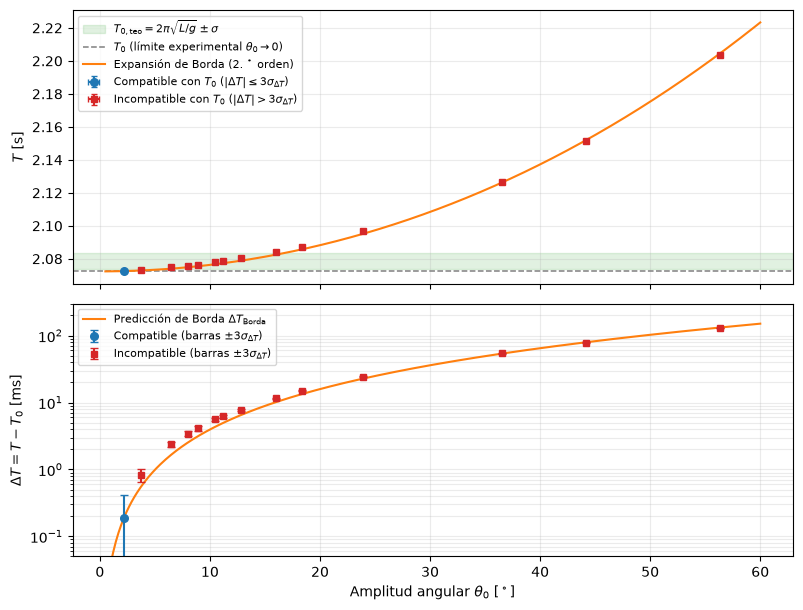

In [20]:
# En Colab se guardan las figuras en ./figures; en el repositorio local Snakemake gestiona docs/figures/
SAVE_FIGURES = not Path("../docs/figures").exists()
FIG_DIR = Path("figures")
if SAVE_FIGURES:
    FIG_DIR.mkdir(parents=True, exist_ok=True)


def exportar_figura_toma(video_name: str, filename: str) -> None:
    """Grafica (y en Colab exporta) θ(t), el ajuste sinusoidal y los residuos sin título interno."""
    info = RESULTADOS[video_name]
    t = info["t"]
    tau = info["tau"]
    tau_fine = np.linspace(0.0, float(tau[-1]), 1400)
    t_fine = float(t[0]) + tau_fine
    fit_fine_deg = np.degrees(modelo_sinusoidal(tau_fine, *info["popt"]))

    fig, (ax_top, ax_bot) = plt.subplots(
        2, 1, figsize=(8.0, 4.5), sharex=True, gridspec_kw={"height_ratios": [2.5, 1.1]}
    )
    ax_top.plot(t, info["theta_deg"], "o", markersize=2.3, color="black", alpha=0.55, label="Datos experimentales")
    ax_top.plot(t_fine, fit_fine_deg, color="#d62728", lw=1.5, label="Ajuste sinusoidal")
    ax_top.set_ylabel(r"$\theta$ [$^\circ$]")
    ax_top.legend(loc="upper right", fontsize=8.5, frameon=True)
    ax_top.grid(True, alpha=0.25)

    ax_bot.plot(t, info["residuos_deg"], "o", markersize=2.0, color="#1f77b4", alpha=0.65)
    ax_bot.axhline(0.0, color="black", linestyle="--", lw=0.9)
    ax_bot.set_ylabel(r"Residuo [$^\circ$]")
    ax_bot.set_xlabel(r"$t$ [s]")
    ax_bot.grid(True, alpha=0.25)

    fig.tight_layout()
    if SAVE_FIGURES:
        out_path = FIG_DIR / filename
        fig.savefig(out_path, dpi=300, bbox_inches="tight")
        print(f"Figura exportada: {out_path}")
    plt.show()


# --- Figuras representativas (Toma 14 y Toma 1) ---
exportar_figura_toma("IMG_1568", "fig_theta_pequena.png")
exportar_figura_toma("IMG_1555", "fig_theta_grande.png")

# --- Figura para §3.2: Período T (lineal) y ΔT = T - T_0 (escala logarítmica en y) ---
df_asc = df_resumen.sort_values("θ_0 [°]", ascending=True)
theta_grid_deg = np.linspace(0.5, 60.0, 500)
theta_grid_rad = np.radians(theta_grid_deg)
T_borda_grid = T0_BORDA_LIM * (
    1.0 + (theta_grid_rad ** 2) / 16.0 + (11.0 * (theta_grid_rad ** 4)) / 3072.0
)
comp_mask = (df_asc["Compatible (3σ)"] == "Sí").to_numpy()

fig, (ax_top, ax_bot) = plt.subplots(
    2, 1, figsize=(8.2, 6.2), sharex=True, gridspec_kw={"height_ratios": [1.3, 1.2]}
)

ax_top.axhspan(
    T0_TEO_L - SIGMA_T0_TEO_L,
    T0_TEO_L + SIGMA_T0_TEO_L,
    color="#2ca02c",
    alpha=0.14,
    label=r"$T_{0,\mathrm{teo}} = 2\pi\sqrt{L/g} \pm \sigma$",
)
ax_top.axhline(
    T0_BORDA_LIM,
    color="gray",
    linestyle="--",
    lw=1.1,
    label=r"$T_0$ (límite experimental $\theta_0 \to 0$)",
)
ax_top.plot(theta_grid_deg, T_borda_grid, color="#ff7f0e", lw=1.5, label=r"Expansión de Borda ($2.^\circ$ orden)")
ax_top.errorbar(
    df_asc["θ_0 [°]"].to_numpy()[comp_mask],
    df_asc["T [s]"].to_numpy()[comp_mask],
    xerr=df_asc["σ_θ0 [°]"].to_numpy()[comp_mask],
    yerr=df_asc["σ_T [s]"].to_numpy()[comp_mask],
    fmt="o", markersize=5.5, color="#1f77b4", capsize=2.5,
    label=r"Compatible con $T_0$ ($|\Delta T| \leq 3\sigma_{\Delta T}$)",
)
ax_top.errorbar(
    df_asc["θ_0 [°]"].to_numpy()[~comp_mask],
    df_asc["T [s]"].to_numpy()[~comp_mask],
    xerr=df_asc["σ_θ0 [°]"].to_numpy()[~comp_mask],
    yerr=df_asc["σ_T [s]"].to_numpy()[~comp_mask],
    fmt="s", markersize=5.0, color="#d62728", capsize=2.5,
    label=r"Incompatible con $T_0$ ($|\Delta T| > 3\sigma_{\Delta T}$)",
)
ax_top.set_ylabel(r"$T$ [s]")
ax_top.legend(loc="upper left", fontsize=8.0, frameon=True)
ax_top.grid(True, alpha=0.25)

ax_bot.plot(
    theta_grid_deg,
    (T_borda_grid - T0_BORDA_LIM) * 1e3,
    color="#ff7f0e",
    lw=1.5,
    label=r"Predicción de Borda $\Delta T_{\mathrm{Borda}}$",
)
ax_bot.errorbar(
    df_asc["θ_0 [°]"].to_numpy()[comp_mask],
    df_asc["ΔT = T - T_0 [ms]"].to_numpy()[comp_mask],
    yerr=df_asc["3σ_ΔT [ms]"].to_numpy()[comp_mask],
    fmt="o", markersize=5.5, color="#1f77b4", capsize=3.0,
    label=r"Compatible (barras $\pm 3\sigma_{\Delta T}$)",
)
ax_bot.errorbar(
    df_asc["θ_0 [°]"].to_numpy()[~comp_mask],
    df_asc["ΔT = T - T_0 [ms]"].to_numpy()[~comp_mask],
    yerr=df_asc["3σ_ΔT [ms]"].to_numpy()[~comp_mask],
    fmt="s", markersize=5.0, color="#d62728", capsize=3.0,
    label=r"Incompatible (barras $\pm 3\sigma_{\Delta T}$)",
)
ax_bot.set_yscale("log")
ax_bot.set_ylim(0.05, 300.0)
ax_bot.set_xlabel(r"Amplitud angular $\theta_0$ [$^\circ$]")
ax_bot.set_ylabel(r"$\Delta T = T - T_0$ [ms]")
ax_bot.legend(loc="upper left", fontsize=8.0, frameon=True)
ax_bot.grid(True, which="both", alpha=0.25)

fig.tight_layout()
if SAVE_FIGURES:
    out_periodo = FIG_DIR / "fig_periodo_vs_amplitud.png"
    fig.savefig(out_periodo, dpi=300, bbox_inches="tight")
    print(f"Figura exportada: {out_periodo}")
plt.show()